# AI feature 4: Topic discovery

**Business question.** Beyond YouTube's broad categories, what kinds of content trend, which belong to one market, and how did the mix change over time?

**Method** (`streampulse/topics.py`):

1. Every unique trending video title (147,000) is turned into a 384-number embedding with `paraphrase-multilingual-MiniLM-L12-v2`, a model that covers 50+ languages including Hindi and Korean (not Tamil or Telugu).
2. BERTopic reduces the embeddings with UMAP, groups them with HDBSCAN (at least 300 videos per topic) and describes each group with its most distinctive words.
3. The smaller Groq model (`openai/gpt-oss-20b`) names each topic from its keywords and 8 example titles.

Titles that do not fit any group well are left as "No clear topic" rather than forced into one.

In [1]:
import re

import matplotlib.dates as mdates
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from streampulse.charts import COUNTRIES, COUNTRY_COLORS, COUNTRY_NAMES, SINGLE_SERIES_COLOR, apply_chart_style
from streampulse.topics import TOPIC_SUMMARY_PATH, VIDEO_TOPICS_PATH

apply_chart_style()
topic_summary = pd.read_csv(TOPIC_SUMMARY_PATH)
video_topics = pd.read_parquet(VIDEO_TOPICS_PATH).merge(topic_summary[["topic", "name"]], on="topic")
video_topics["first_trending_date"] = pd.to_datetime(video_topics["first_trending_date"])
named = topic_summary[topic_summary["topic"] >= 0]
print(f"{len(video_topics):,} videos, {len(named)} topics, "
      f"{100 * (video_topics['topic'] == -1).mean():.1f}% with no clear topic")

147,000 videos, 56 topics, 48.4% with no clear topic


## 1. What the unassigned half is

Nearly half of all titles fall in no topic. Their most distinctive words show what they are.

In [2]:
topic_summary.loc[topic_summary["topic"] == -1, ["videos", "keywords", "example_titles"]]

,videos,keywords,example_titles
0,71218,"episode, ep, serial, promo, tv, 2023, tamil, 2021",NEW! Taarak Mehta Ka Ooltah Chashmah - Ep 3733...


They are mostly Indian TV serial episodes and promos. Each show has its own name and episode number, and Tamil and Telugu are not covered by the embedding model, so these titles do not form tight groups. Short, varied titles commonly leave a large unassigned group with this method.

## 2. The largest topics

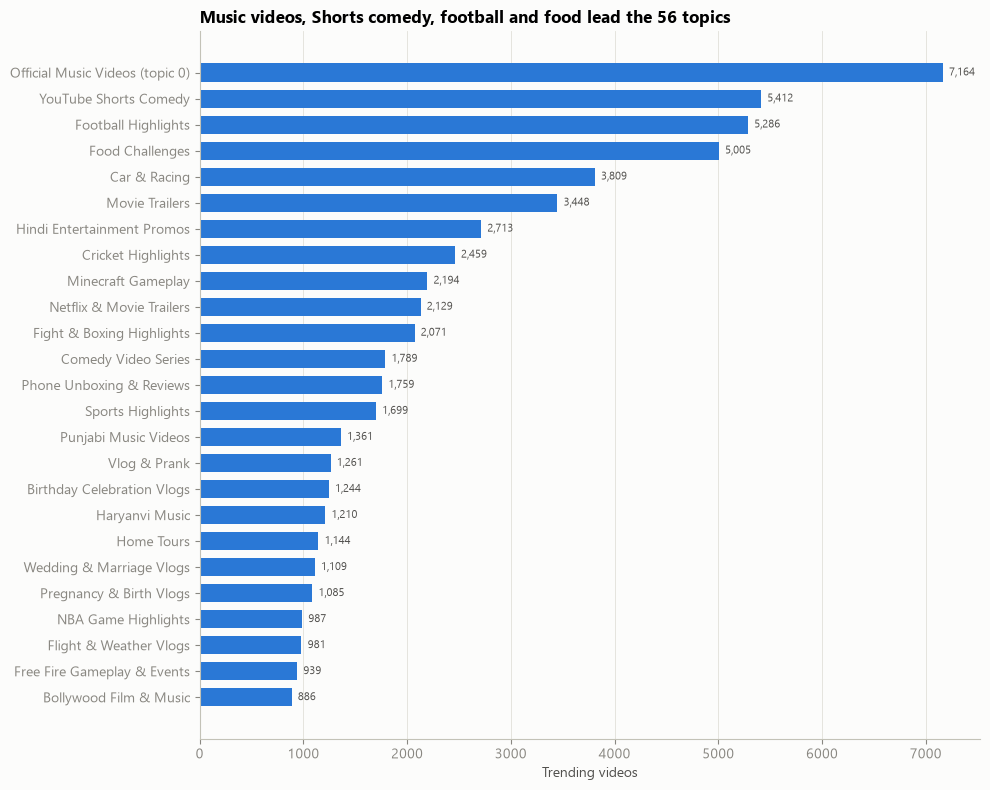

In [3]:
largest = named.nlargest(25, "videos").iloc[::-1]

fig, ax = plt.subplots(figsize=(10, 8))
ax.barh(largest["name"], largest["videos"], color=SINGLE_SERIES_COLOR, height=0.7)
for y_position, videos in enumerate(largest["videos"]):
    ax.text(videos + 60, y_position, f"{videos:,}", va="center", fontsize=8, color="#52514e")
ax.set_xlabel("Trending videos")
ax.grid(axis="y", visible=False)
ax.set_title("Music videos, Shorts comedy, football and food lead the 56 topics")
plt.tight_layout()
plt.show()

## 3. Topics by market

Share of each topic's videos that trended in India, and in the US or UK (a video can count for both).

16 topics are at least 90% Indian, 12 at least 90% US/UK, 28 mixed


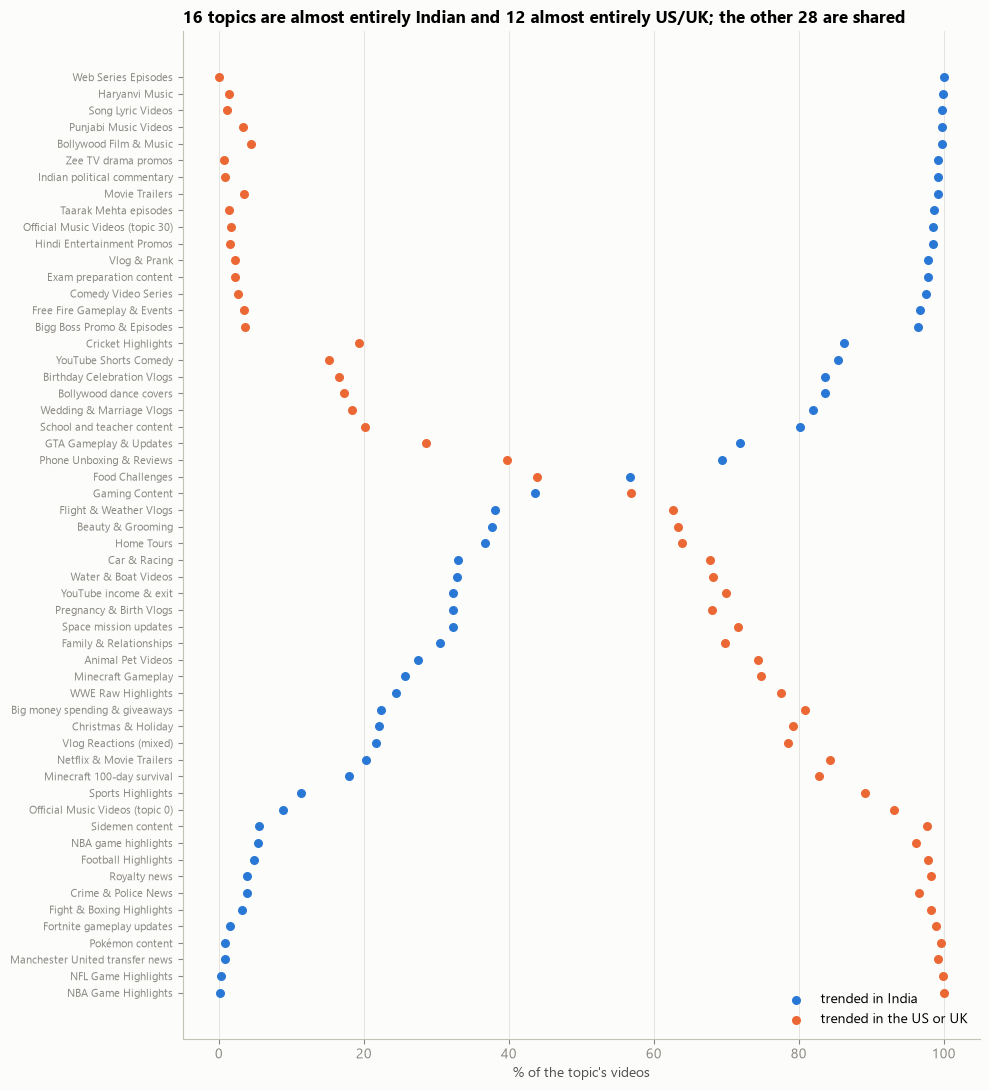

,videos,pct_india,pct_us_or_uk
name,,,
Animal Pet Videos,614,27.5,74.4
Beauty & Grooming,575,37.7,63.3
Big money spending & giveaways,371,22.4,80.9
Birthday Celebration Vlogs,1244,83.7,16.6
Bollywood dance covers,447,83.7,17.2
Car & Racing,3809,33.0,67.8
Christmas & Holiday,557,22.1,79.2
Cricket Highlights,2459,86.3,19.3
Family & Relationships,586,30.5,69.8


In [4]:
video_topics["in_india"] = video_topics["countries"].str.contains("IN")
video_topics["in_us_or_uk"] = video_topics["countries"].str.contains("US|GB")
topic_markets = (
    video_topics[video_topics["topic"] >= 0].groupby("name")
    .agg(videos=("video_id", "size"), pct_india=("in_india", "mean"), pct_us_or_uk=("in_us_or_uk", "mean"))
)
topic_markets[["pct_india", "pct_us_or_uk"]] *= 100
india_topics = (topic_markets["pct_india"] >= 90).sum()
us_uk_topics = (topic_markets["pct_us_or_uk"] >= 90).sum()
print(f"{india_topics} topics are at least 90% Indian, {us_uk_topics} at least 90% US/UK, "
      f"{len(topic_markets) - india_topics - us_uk_topics} mixed")

ordered = topic_markets.sort_values("pct_india")
fig, ax = plt.subplots(figsize=(10, 11))
ax.scatter(ordered["pct_india"], range(len(ordered)), color=COUNTRY_COLORS["IN"], s=30, label="trended in India", zorder=3)
ax.scatter(ordered["pct_us_or_uk"], range(len(ordered)), color=COUNTRY_COLORS["US"], s=30, label="trended in the US or UK", zorder=3)
ax.set_yticks(range(len(ordered)), ordered.index, fontsize=8)
ax.set_xlabel("% of the topic's videos")
ax.grid(axis="y", visible=False)
ax.set_title("16 topics are almost entirely Indian and 12 almost entirely US/UK; the other 28 are shared")
ax.legend(loc="lower right")
plt.tight_layout()
plt.show()

topic_markets[(topic_markets["pct_india"] < 90) & (topic_markets["pct_us_or_uk"] < 90)].round(1)

## 4. YouTube Shorts left the trending lists in 2022

"YouTube Shorts comedy" was the topic whose share fell most from 2021 to 2023. Counting titles tagged `#shorts` per month shows why: Shorts disappeared from the US and UK lists around April 2022 and from India's in October 2022. This explains the break in India's engagement data on 6 October 2022 found in analysis 3.

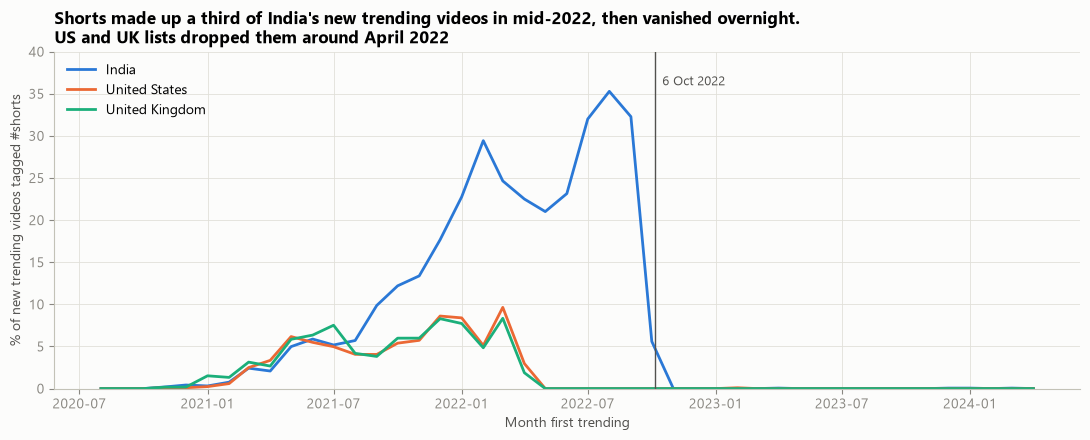

country,IN,US,GB
month,,,
2022-01-01,22.8,8.4,7.7
2022-02-01,29.4,5.1,4.8
2022-03-01,24.6,9.6,8.3
2022-04-01,22.5,3.0,1.9
2022-05-01,21.0,0.0,0.0
2022-06-01,23.1,0.0,0.0
2022-07-01,32.0,0.0,0.0
2022-08-01,35.3,0.0,0.0
2022-09-01,32.3,0.0,0.0


In [5]:
is_shorts = video_topics["title"].str.lower().str.contains(r"#shorts?\b")
monthly_shorts = (
    video_topics.assign(month=video_topics["first_trending_date"].dt.to_period("M").dt.to_timestamp(),
                        is_shorts=is_shorts)
    .assign(country=lambda rows: rows["countries"].str.split("+"))
    .explode("country")
    .groupby(["month", "country"])["is_shorts"].mean().mul(100).unstack("country")[COUNTRIES]
)

fig, ax = plt.subplots(figsize=(11, 4.5))
for country in COUNTRIES:
    ax.plot(monthly_shorts.index, monthly_shorts[country], color=COUNTRY_COLORS[country], label=COUNTRY_NAMES[country])
india_change = mdates.date2num(pd.Timestamp("2022-10-06").to_pydatetime())
ax.axvline(india_change, color="#52514e", linewidth=1)
ax.text(india_change + 10, 36, "6 Oct 2022", fontsize=9, color="#52514e")
ax.set_ylim(0, 40)
ax.set_ylabel("% of new trending videos tagged #shorts")
ax.set_xlabel("Month first trending")
ax.set_title("Shorts made up a third of India's new trending videos in mid-2022, then vanished overnight.\n"
             "US and UK lists dropped them around April 2022")
ax.legend(loc="upper left")
plt.tight_layout()
plt.show()

monthly_shorts.loc["2022-01":"2022-12"].round(1)

## 5. How the topic mix changed

Share of each year's new trending videos per topic, 2021 against 2023 (the two full years either side of the Shorts change).

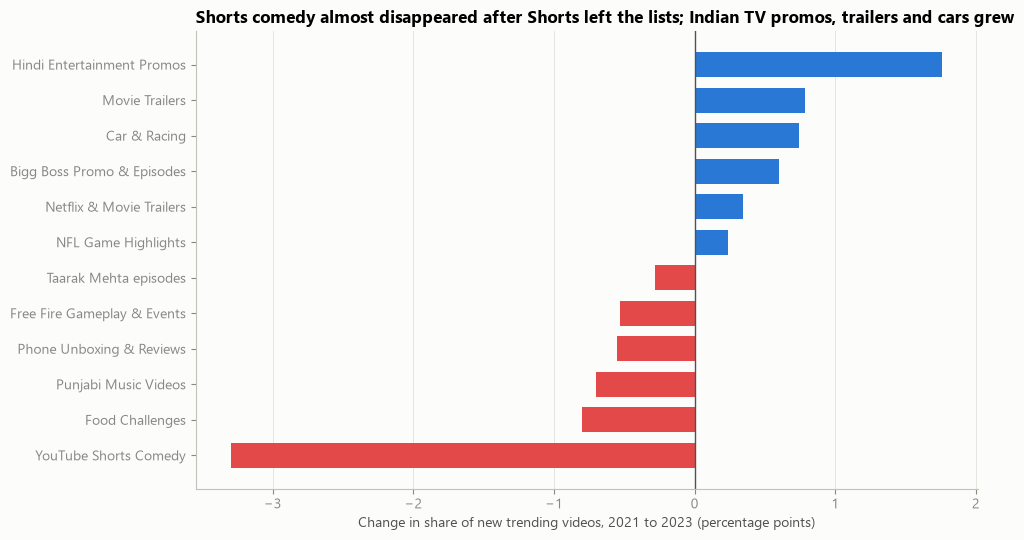

first_trending_date,2021,2022,2023
name,,,
YouTube Shorts Comedy,3.48,9.30,0.18
Food Challenges,3.85,3.38,3.04
Punjabi Music Videos,1.33,0.71,0.63
Phone Unboxing & Reviews,1.31,1.19,0.76
Free Fire Gameplay & Events,0.95,0.70,0.42
Taarak Mehta episodes,0.51,0.19,0.23
NFL Game Highlights,0.39,0.60,0.63
Netflix & Movie Trailers,1.27,1.50,1.61
Bigg Boss Promo & Episodes,0.31,0.27,0.92


In [6]:
yearly_share = pd.crosstab(video_topics["name"], video_topics["first_trending_date"].dt.year, normalize="columns") * 100
change = (yearly_share[2023] - yearly_share[2021]).drop("No clear topic").sort_values()
movers = pd.concat([change.head(6), change.tail(6)])

fig, ax = plt.subplots(figsize=(10, 5.5))
ax.barh(movers.index, movers, color=["#e34948" if value < 0 else SINGLE_SERIES_COLOR for value in movers], height=0.7)
ax.axvline(0, color="#52514e", linewidth=1)
ax.set_xlabel("Change in share of new trending videos, 2021 to 2023 (percentage points)")
ax.grid(axis="y", visible=False)
ax.set_title("Shorts comedy almost disappeared after Shorts left the lists; Indian TV promos, trailers and cars grew")
plt.tight_layout()
plt.show()

yearly_share.loc[movers.index, [2021, 2022, 2023]].round(2)

Some topics are seasonal. Monthly counts of new trending videos for four of them:

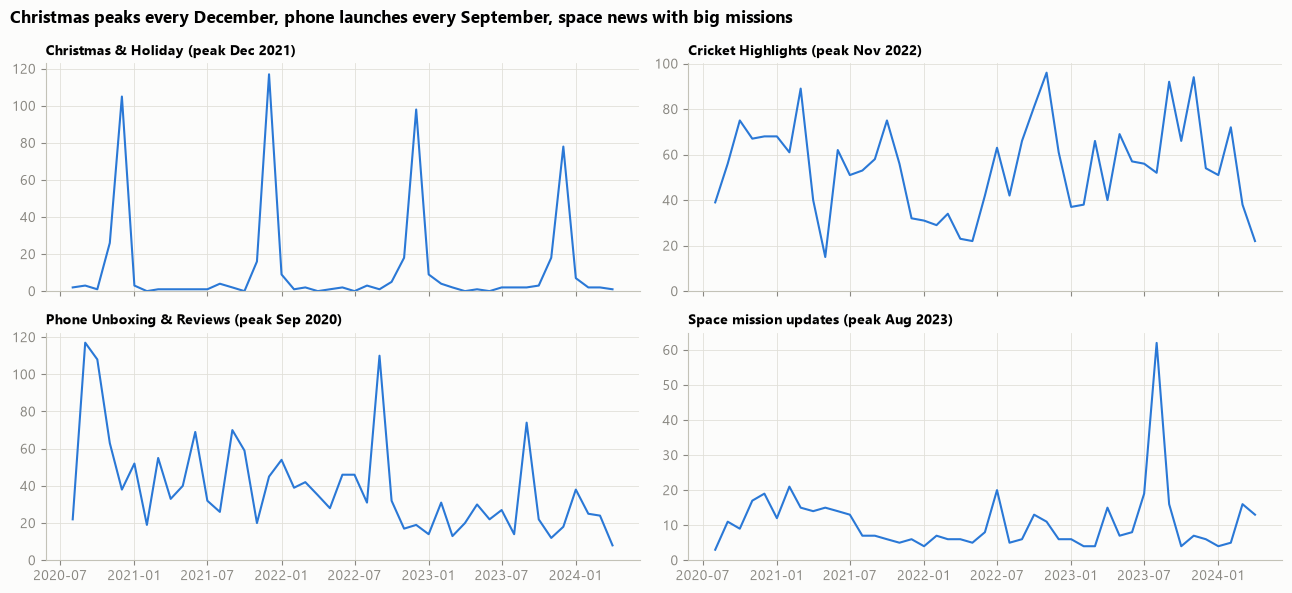

In [7]:
seasonal_topics = ["Christmas & Holiday", "Cricket Highlights", "Phone Unboxing & Reviews", "Space mission updates"]
monthly_counts = (
    video_topics[video_topics["name"].isin(seasonal_topics)]
    .assign(month=lambda rows: rows["first_trending_date"].dt.to_period("M").dt.to_timestamp())
    .groupby(["month", "name"]).size().unstack("name").fillna(0)
)

fig, axes = plt.subplots(2, 2, figsize=(13, 6), sharex=True)
for ax, topic_name in zip(axes.ravel(), seasonal_topics):
    ax.plot(monthly_counts.index, monthly_counts[topic_name], color=SINGLE_SERIES_COLOR, linewidth=1.5)
    peak_month = monthly_counts[topic_name].idxmax()
    ax.set_title(f"{topic_name} (peak {peak_month:%b %Y})", fontsize=10)
    ax.set_ylim(0, None)
fig.suptitle("Christmas peaks every December, phone launches every September, space news with big missions",
             x=0.01, ha="left", fontweight="bold")
plt.tight_layout()
plt.show()

## Finding

**Topic discovery finds 56 recognisable kinds of trending content, shows most belong to one market, and explains the India data break: YouTube Shorts left the trending lists in 2022.**

- **Coverage.** 56 topics across 147,000 trending titles; 48.4% of titles fit no topic, mostly Indian TV serial episodes and promos with unique show names, often in scripts the embedding model does not cover.
- **Largest topics:** official music videos (7,164 videos), YouTube Shorts comedy (5,412), football highlights (5,286) and food challenges and recipes (5,005).
- **Markets.** 16 topics are at least 90% Indian (Hindi TV promos, Punjabi and Haryanvi music, Bollywood, Indian political commentary, Indian movie trailers) and 12 at least 90% US/UK (NBA, NFL, Manchester United transfer news, Pokémon, Fortnite, boxing, royal news). The other 28 are shared, such as food challenges (57% of videos trended in India, 44% in the US or UK).
- **Shorts.** Titles tagged `#shorts` were 32% to 35% of India's new trending videos from July to September 2022 and none after 6 October 2022; in the US and UK they peaked near 10% and were gone by May 2022. On 5 October 2022 India's list held 79 Shorts out of 200; on 6 October, none. This explains the break in India's engagement data found in analysis 3.
- **Change in mix, 2021 to 2023:** YouTube Shorts comedy fell from 3.5% to 0.2% of new trending videos; Hindi entertainment promos rose from 1.1% to 2.9%, movie trailers from 2.0% to 2.8%, car and racing from 2.4% to 3.1%.
- **Seasonality.** Christmas content peaks every December, phone unboxings in September (launch month), and space content peaked in August 2023, the month of the Chandrayaan-3 landing that anomaly detection also flags.

**Limitations**

- Half of the titles have no topic, so topic shares describe the other half.
- Topic boundaries depend on settings (at least 300 videos per topic) and random seeds; a different setting would split or merge some topics.
- Topic names come from an LLM reading 8 example titles; broad topics can contain some unrelated titles.
- Shorts are counted from the `#shorts` tag in titles, so Shorts without the tag are missed.